# Lab 07 — Transformer Architecture

IMDb sentiment classification. Transformer được học từ đầu, không dùng pretrained model.

## Thiết lập

In [1]:
from collections import Counter
from copy import deepcopy
from pathlib import Path
from time import perf_counter
import math
import random
import re
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

LAB_DIR = Path.cwd().resolve()
if LAB_DIR.name != 'lab07':
    LAB_DIR = LAB_DIR / 'labs' / 'lab07'
REPO_ROOT = LAB_DIR.parents[1]
sys.path.insert(0, str(LAB_DIR))
from positional_encoding import PositionalEncoding, sinusoidal_encoding
from transformer_block import TransformerBlock

SEED = 42
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_num_threads(min(4, torch.get_num_threads()))
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
pd.set_option('display.max_colwidth', 180)
print('Device:', DEVICE, '| PyTorch:', torch.__version__)

Device: cpu | PyTorch: 2.14.1+cpu


## 6–7. Attention head và concatenation

Đề chỉ cho shape của các ma trận. Phần tính ký hiệu và một ví dụ số được ghi trong calculations.md. Với hai head dimension 2, concatenation tạo vector dimension 4, sau đó WO học cách trộn thông tin giữa các head.

In [2]:
X = torch.tensor([[1.,0.,0.,0.], [0.,1.,0.,0.], [1.,1.,0.,0.]])
W = torch.tensor([[1.,0.], [0.,1.], [0.,0.], [0.,0.]])
Q = K = V = X @ W
S = Q @ K.T / math.sqrt(2)
A = torch.softmax(S, dim=-1)
print('Q = K = V:', Q.numpy(), sep='\n')
print('Scaled scores:', S.numpy().round(4), sep='\n')
print('Weights:', A.numpy().round(4), sep='\n')
print('Context:', (A @ V).numpy().round(4), sep='\n')

Q = K = V:
[[1. 0.]
 [0. 1.]
 [1. 1.]]
Scaled scores:
[[0.7071 0.     0.7071]
 [0.     0.7071 0.7071]
 [0.7071 0.7071 1.4142]]
Weights:
[[0.4011 0.1978 0.4011]
 [0.1978 0.4011 0.4011]
 [0.2483 0.2483 0.5035]]
Context:
[[0.8022 0.5989]
 [0.5989 0.8022]
 [0.7517 0.7517]]


## 9–11. Experiment 1 — Positional encoding

,PE0,PE1,PE2,PE3
0,0.000000,1.000000,0.000000,1.00000
1,0.841471,0.540302,0.010000,0.99995
2,0.909297,-0.416147,0.019999,0.99980


I love NLP


,E0,E1,E2,E3,E+PE0,E+PE1,E+PE2,E+PE3
0,1.0,0.0,0.0,0.0,1.000000,1.000000,0.000000,1.00000
1,0.0,1.0,0.0,0.0,0.841471,1.540302,0.010000,0.99995
2,0.0,0.0,1.0,0.0,0.909297,-0.416147,1.019999,0.99980


NLP love I


,E0,E1,E2,E3,E+PE0,E+PE1,E+PE2,E+PE3
0,0.0,0.0,1.0,0.0,0.000000,1.000000,1.000000,1.00000
1,0.0,1.0,0.0,0.0,0.841471,1.540302,0.010000,0.99995
2,1.0,0.0,0.0,0.0,1.909297,-0.416147,0.019999,0.99980


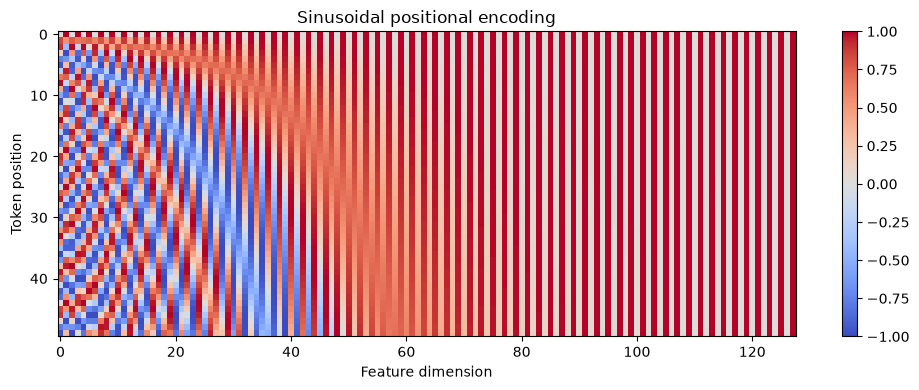

In [3]:
display(pd.DataFrame(sinusoidal_encoding(3, 4).numpy(), index=[0,1,2], columns=['PE0','PE1','PE2','PE3']))
toy_embedding = torch.tensor([[1.,0.,0.,0.], [0.,1.,0.,0.], [0.,0.,1.,0.]])
pe_small = sinusoidal_encoding(3, 4)
for order, name in [([0,1,2], 'I love NLP'), ([2,1,0], 'NLP love I')]:
    print(name)
    display(pd.DataFrame(torch.cat([toy_embedding[order], toy_embedding[order] + pe_small], dim=1).numpy(),
                         columns=['E0','E1','E2','E3','E+PE0','E+PE1','E+PE2','E+PE3']))
fig, ax = plt.subplots(figsize=(10, 4))
im = ax.imshow(sinusoidal_encoding(50,128).numpy(), cmap='coolwarm', aspect='auto', vmin=-1, vmax=1)
ax.set(xlabel='Feature dimension', ylabel='Token position', title='Sinusoidal positional encoding')
fig.colorbar(im, ax=ax)
fig.tight_layout()
fig.savefig(LAB_DIR / 'positional_encoding.png', dpi=160)
plt.show()

**Trả lời:** Không có positional information, cùng một token nhận cùng embedding dù đổi vị trí. Cộng PE đưa chỉ số vị trí vào input; hai bảng trên cho thấy embedding sau cộng PE thay đổi theo vị trí.

## 12. Permutation experiment

In [2]:
torch.manual_seed(SEED)
permutation_block = TransformerBlock(8, 2, 16, dropout=0).eval()
embedding_generator = torch.Generator().manual_seed(SEED)
token_embeddings = {token: torch.randn(8, generator=embedding_generator)
                    for token in ['I', 'love', 'NLP', 'dog', 'bites', 'man']}
permutation_rows = []
for first, second in [('I love NLP', 'NLP love I'), ('dog bites man', 'man bites dog')]:
    original = torch.stack([token_embeddings[token] for token in first.split()]).unsqueeze(0)
    reversed_input = torch.stack([token_embeddings[token] for token in second.split()]).unsqueeze(0)
    for use_pe in [False, True]:
        pe = sinusoidal_encoding(3,8).unsqueeze(0) if use_pe else torch.zeros_like(original)
        with torch.no_grad():
            left = permutation_block(original + pe)
            right = permutation_block(reversed_input + pe)
        aligned_diff = (left - right[:,[2,1,0]]).abs().max().item()
        pooled_diff = (left.mean(1) - right.mean(1)).abs().max().item()
        permutation_rows.append({'S1':first, 'S2':second, 'PE':use_pe,
                                 'aligned_token_max_diff':aligned_diff, 'mean_representation_max_diff':pooled_diff})
permutation_table = pd.DataFrame(permutation_rows)
display(permutation_table)
assert permutation_table.loc[~permutation_table.PE, 'mean_representation_max_diff'].max() < 1e-5
assert permutation_table.loc[permutation_table.PE, 'mean_representation_max_diff'].min() > 1e-5

,S1,S2,PE,aligned_token_max_diff,mean_representation_max_diff
0,I love NLP,NLP love I,False,2.384186e-07,1.192093e-07
1,I love NLP,NLP love I,True,1.444548e+00,1.467504e-01
2,dog bites man,man bites dog,False,3.576279e-07,2.384186e-07
3,dog bites man,man bites dog,True,1.411224e+00,8.395781e-02


**Trả lời:** Khi không sử dụng Positional Encoding, Self-Attention có tính chất hoán đổi đầu ra tương ứng với thứ tự token đầu vào. Vì vậy, sau mean pooling, representation của hai cách sắp xếp gần như giống nhau, chỉ khác do sai số tính toán.

Khi cộng Positional Encoding, các token nhận thêm thông tin vị trí, nên representation sau khi đảo thứ tự có thể khác nhau. Kết quả thực nghiệm minh họa vai trò của positional information trong Transformer.

Đây là thí nghiệm sử dụng vector ngẫu nhiên và Transformer Block chưa huấn luyện, không phải bằng chứng model hiểu ngữ nghĩa của hai câu.

## 13–14. Feed-forward network

FFN biến đổi phi tuyến từng token. Bài FFN cho h = [1,1]; đề thiếu W2 và b2 nên y chỉ được xác định dưới dạng ký hiệu trong calculations.md.

## 15–16. Residual và LayerNorm

Chỉ dùng F(x) thì output hoàn toàn đi qua phép biến đổi. Với x + F(x), input có thêm một đường truyền trực tiếp tới output và hỗ trợ gradient khi training.

LayerNorm chuẩn hóa theo feature dimension của từng token, không chuẩn hóa chung các review trong batch.

## 17–18. Transformer block và kiểm tra shape

Block tự ghép: Multi-Head Self-Attention → Add & LayerNorm → FFN → Add & LayerNorm. Implementation dùng Linear, Softmax, Dropout, LayerNorm; không gọi TransformerEncoderLayer hoặc MultiheadAttention.

In [5]:
torch.manual_seed(SEED)
shape_block = TransformerBlock(128,4,256,dropout=0).eval()
shape_input = torch.randn(8,100,128)
with torch.no_grad():
    shape_output, shape_weights = shape_block(shape_input, return_attention=True)
shape_rows = [
    ('X',(8,100,128)), ('Q/K/V projected',(8,100,128)), ('Q/K/V split',(8,4,100,32)),
    ('Scores/weights',tuple(shape_weights.shape)), ('Context per head',(8,4,100,32)),
    ('Concatenated/output projection',(8,100,128)), ('FFN hidden',(8,100,256)),
    ('FFN output',(8,100,128)), ('Block output',tuple(shape_output.shape))]
display(pd.DataFrame(shape_rows, columns=['tensor','shape']))
assert shape_output.shape == shape_input.shape
assert torch.allclose(shape_weights.sum(-1), torch.ones(8,4,100), atol=1e-6)

,tensor,shape
0,X,"(8, 100, 128)"
1,Q/K/V projected,"(8, 100, 128)"
2,Q/K/V split,"(8, 4, 100, 32)"
3,Scores/weights,"(8, 4, 100, 100)"
4,Context per head,"(8, 4, 100, 32)"
5,Concatenated/output projection,"(8, 100, 128)"
6,FFN hidden,"(8, 100, 256)"
7,FFN output,"(8, 100, 128)"
8,Block output,"(8, 100, 128)"


## IMDb dataset và cấu hình dùng chung

Dùng lại các split đã loại duplicate ở Lab 04. Tập con cân bằng gồm 1.800 train, 600 validation, 600 test (60/20/20); mọi thí nghiệm giữ cùng các review. Vocabulary chỉ xây từ train. Giới hạn số mẫu để chạy các cấu hình trên CPU.

In [6]:
def tokenize(text):
    return re.findall(r"[a-z0-9']+", str(text).lower())

DATA_DIR = REPO_ROOT / 'labs' / 'lab04' / 'data'
source_splits = {name:pd.read_csv(DATA_DIR/f'imdb_{name}.csv.gz') for name in ['train','validation','test']}
def balanced_sample(frame, per_class):
    result = pd.concat([frame[frame.label==label].sample(n=per_class, random_state=SEED) for label in [0,1]])
    return result.sample(frac=1, random_state=SEED).reset_index(drop=True)
splits = {name:balanced_sample(source_splits[name], count) for name,count in [('train',900),('validation',300),('test',300)]}
tokenized = {name:[tokenize(text) for text in frame.text] for name,frame in splits.items()}
PAD, UNK, CLS = 0,1,2
vocabulary = {'<pad>':PAD, '<unk>':UNK, '<cls>':CLS}
counts = Counter(word for tokens in tokenized['train'] for word in tokens)
for word,_ in counts.most_common(8000-len(vocabulary)):
    vocabulary[word] = len(vocabulary)
D_MODEL, D_FF, BATCH_SIZE, EPOCHS, LEARNING_RATE = 128,256,32,5,0.001
display(pd.DataFrame([{'split':name,'samples':len(frame),'negative':int((frame.label==0).sum()),'positive':int((frame.label==1).sum())} for name,frame in splits.items()]))
print('vocabulary:',len(vocabulary), '| embedding dimension:',D_MODEL,'| batch:',BATCH_SIZE,
      '| epochs:',EPOCHS,'| optimizer: Adam | learning rate:',LEARNING_RATE)

def encode_tokens(tokens, length):
    ids = [vocabulary.get(word,UNK) for word in tokens[:length]]
    if not ids:
        ids = [UNK]
    mask = [True]*len(ids)
    ids += [PAD]*(length-len(ids))
    mask += [False]*(length-len(mask))
    return ids,mask

def make_loaders(length):
    loaders = {}
    for name in splits:
        encoded = [encode_tokens(tokens,length) for tokens in tokenized[name]]
        data = TensorDataset(torch.tensor([x[0] for x in encoded]), torch.tensor([x[1] for x in encoded]),
                             torch.tensor(splits[name].label.to_numpy(),dtype=torch.long))
        loaders[name] = DataLoader(data, batch_size=BATCH_SIZE, shuffle=name=='train',
                                   generator=torch.Generator().manual_seed(SEED))
    return loaders

,split,samples,negative,positive
0,train,1800,900,900
1,validation,600,300,300
2,test,600,300,300


vocabulary: 8000 | embedding dimension: 128 | batch: 32 | epochs: 5 | optimizer: Adam | learning rate: 0.001


## Model và training loop

Tất cả Transformer dùng một block, sinusoidal PE và một token CLS học từ đầu ở đầu sequence. Mean pooling bỏ CLS và padding; CLS-style pooling lấy output của CLS. Nhờ đó hai cách pooling dùng cùng input và cùng số tham số. LSTM dùng cùng embedding dimension, các review, optimizer, learning rate, batch size và số epoch.

In [7]:
class TransformerClassifier(nn.Module):
    def __init__(self, n_heads=4, pooling='mean'):
        super().__init__()
        self.embedding = nn.Embedding(len(vocabulary),D_MODEL,padding_idx=PAD)
        self.position = PositionalEncoding(D_MODEL,1024)
        self.input_dropout = nn.Dropout(0.1)
        self.block = TransformerBlock(D_MODEL,n_heads,D_FF,dropout=0.1)
        self.classifier = nn.Linear(D_MODEL,2)
        self.pooling = pooling

    def forward(self, ids, mask, return_attention=False):
        cls_ids = torch.full((ids.shape[0],1),CLS,dtype=ids.dtype,device=ids.device)
        ids = torch.cat([cls_ids,ids],dim=1)
        cls_mask = torch.ones(mask.shape[0],1,dtype=torch.bool,device=mask.device)
        full_mask = torch.cat([cls_mask,mask],dim=1)
        embedded = self.input_dropout(self.position(self.embedding(ids)))
        hidden, weights = self.block(embedded,full_mask,return_attention=True)
        if self.pooling == 'cls':
            pooled = hidden[:,0]
        else:
            pooled = (hidden[:,1:]*mask.unsqueeze(-1)).sum(1)/mask.sum(1,keepdim=True)
        logits = self.classifier(pooled)
        return (logits,weights) if return_attention else logits


class LSTMClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.embedding = nn.Embedding(len(vocabulary),D_MODEL,padding_idx=PAD)
        self.input_dropout = nn.Dropout(0.1)
        self.lstm = nn.LSTM(D_MODEL,D_MODEL,batch_first=True)
        self.classifier = nn.Linear(D_MODEL,2)

    def forward(self, ids, mask):
        embedded = self.input_dropout(self.embedding(ids))
        packed = nn.utils.rnn.pack_padded_sequence(embedded,mask.sum(1).cpu(),batch_first=True,enforce_sorted=False)
        _,(hidden,_) = self.lstm(packed)
        return self.classifier(hidden[-1])


def metrics(target,prediction):
    return {'accuracy':accuracy_score(target,prediction),'precision':precision_score(target,prediction,zero_division=0),
            'recall':recall_score(target,prediction,zero_division=0),'f1':f1_score(target,prediction,zero_division=0)}


def evaluate(model, loader):
    model.eval()
    truth, predicted, positive = [],[],[]
    total_loss = 0.
    with torch.no_grad():
        for ids,mask,labels in loader:
            ids,mask,labels = ids.to(DEVICE),mask.to(DEVICE),labels.to(DEVICE)
            logits = model(ids,mask)
            total_loss += nn.functional.cross_entropy(logits,labels,reduction='sum').item()
            truth.extend(labels.cpu().tolist())
            predicted.extend(logits.argmax(-1).cpu().tolist())
            positive.extend(logits.softmax(-1)[:,1].cpu().tolist())
    return {'metrics':metrics(truth,predicted),'loss':total_loss/len(truth),
            'truth':np.array(truth),'prediction':np.array(predicted),'p_positive':np.array(positive)}


runs = {}
def train_run(kind='Transformer', heads=4, length=64, pooling='mean'):
    key = (kind,heads if kind=='Transformer' else 0,length,pooling)
    if key in runs:
        return runs[key]
    torch.manual_seed(SEED)
    np.random.seed(SEED)
    model = (TransformerClassifier(heads,pooling) if kind=='Transformer' else LSTMClassifier()).to(DEVICE)
    loaders = make_loaders(length)
    optimizer = torch.optim.Adam(model.parameters(),lr=LEARNING_RATE)
    best_f1, best_state, best_epoch = -1., None, None
    history = []
    if DEVICE.type == 'cuda':
        torch.cuda.synchronize()
    start = perf_counter()
    for epoch in range(1,EPOCHS+1):
        model.train()
        total_loss = 0.
        for ids,mask,labels in loaders['train']:
            ids,mask,labels = ids.to(DEVICE),mask.to(DEVICE),labels.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            logits = model(ids,mask)
            loss = nn.functional.cross_entropy(logits,labels)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(),1.)
            optimizer.step()
            total_loss += loss.item()*len(labels)
        validation = evaluate(model,loaders['validation'])
        history.append({'epoch':epoch,'training_loss':total_loss/len(splits['train']),
                        'validation_loss':validation['loss'],'validation_f1':validation['metrics']['f1']})
        if validation['metrics']['f1'] > best_f1:
            best_f1 = validation['metrics']['f1']
            best_state = {name:value.detach().cpu().clone() for name,value in model.state_dict().items()}
            best_epoch = epoch
    if DEVICE.type == 'cuda':
        torch.cuda.synchronize()
    elapsed = perf_counter()-start
    model.load_state_dict(best_state)
    test = evaluate(model,loaders['test'])
    result = {'key':key,'model':model,'parameters':sum(p.numel() for p in model.parameters()),
              'training_time_sec':elapsed,'test':test,'best_validation_f1':best_f1,
              'best_epoch':best_epoch,'history':pd.DataFrame(history)}
    runs[key] = result
    print(kind,'heads=',key[1],'length=',length,'pooling=',pooling if kind=='Transformer' else 'final_hidden',
          'test F1=',round(test['metrics']['f1'],4),'time=',round(elapsed,2),'s',flush=True)
    return result


def result_row(experiment,run):
    kind,heads,length,pooling = run['key']
    return {'experiment':experiment,'model':kind,'heads':heads,'d_model':D_MODEL,
            'd_k':D_MODEL//heads if heads else np.nan,'max_length':length,'pooling':pooling if kind=='Transformer' else 'final_hidden',
            'parameters':run['parameters'],'training_time_sec':round(run['training_time_sec'],3),
            'epochs':EPOCHS,'best_epoch':run['best_epoch'],'validation_f1':round(run['best_validation_f1'],6),
            'train_samples':len(splits['train']),'validation_samples':len(splits['validation']),
            'test_samples':len(splits['test']),'vocabulary_size':len(vocabulary),
            **{key:round(value,6) for key,value in run['test']['metrics'].items()}}

## 19. Experiment 2 — Number of attention heads

In [8]:
head_runs = {heads:train_run(heads=heads) for heads in [1,2,4,8]}
base_run = head_runs[4]
base_model = base_run['model']
head_table = pd.DataFrame([result_row('heads',run) for run in head_runs.values()])
display(head_table[['heads','d_k','parameters','training_time_sec','accuracy','f1']])

Transformer heads= 1 length= 64 pooling= mean test F1= 0.7128 time= 14.18 s


Transformer heads= 2 length= 64 pooling= mean test F1= 0.7065 time= 13.52 s


Transformer heads= 4 length= 64 pooling= mean test F1= 0.6795 time= 15.57 s


Transformer heads= 8 length= 64 pooling= mean test F1= 0.7048 time= 20.78 s


,heads,d_k,parameters,training_time_sec,accuracy,f1
0,1,128,1156738,14.180,0.633333,0.712794
1,2,64,1156738,13.522,0.631667,0.706507
2,4,32,1156738,15.566,0.666667,0.679487
3,8,16,1156738,20.778,0.630000,0.704787


**Trả lời:** d_model giữ ở 128 nên tổng dimension không tăng khi thêm head. dk giảm từ 128 xuống 64, 32, 16 và số tham số vẫn là 1.156.738. Accuracy lần lượt là 0.6333, 0.6317, 0.6667, 0.6300 nên không tăng đều theo số head. Head 4 có accuracy cao nhất, nhưng cấu hình 1 head có F1 cao nhất trong bảng; không có cấu hình tốt nhất theo mọi metric.

## 20. Experiment 3 — Attention head diversity

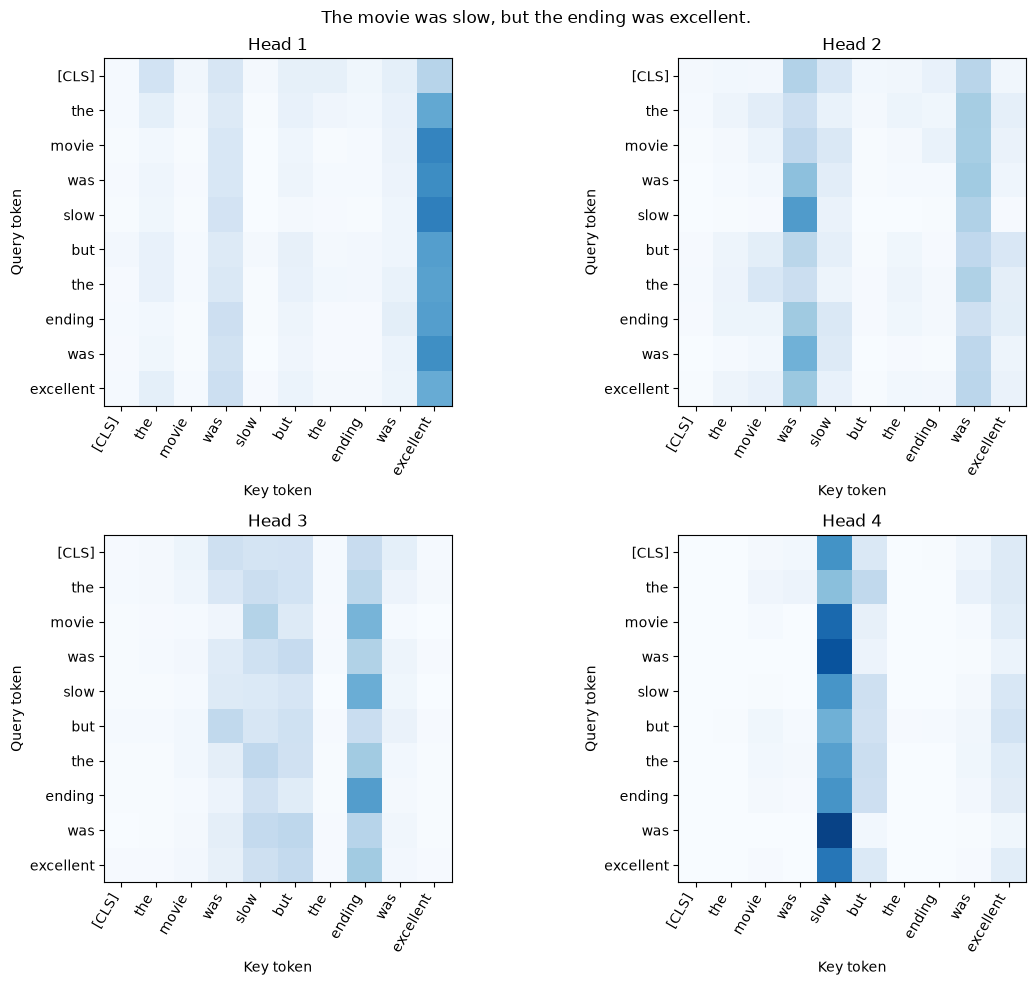

,head,mean_max_weight,mean_entropy_nats,normalized_entropy
0,1,0.566952,1.403028,0.609327
1,2,0.384448,1.645362,0.714572
2,3,0.365801,1.617248,0.702362
3,4,0.661564,1.022541,0.444084


,1,2,3,4
1,1.000000,0.403714,0.151190,0.187337
2,0.403714,1.000000,0.360265,0.261742
3,0.151190,0.360265,1.000000,0.495971
4,0.187337,0.261742,0.495971,1.000000


Most focused head: 4
Most diffuse head: 2


In [9]:
head_sentence = 'The movie was slow, but the ending was excellent.'
head_words = tokenize(head_sentence)
head_ids,head_mask = encode_tokens(head_words,64)
base_model.eval()
with torch.no_grad():
    _,head_weights = base_model(torch.tensor([head_ids],device=DEVICE),
                               torch.tensor([head_mask],device=DEVICE),return_attention=True)
head_tokens = ['[CLS]']+head_words
head_matrices = head_weights[0,:,:len(head_tokens),:len(head_tokens)].cpu().numpy()
fig,axes = plt.subplots(2,2,figsize=(12,10))
head_statistics = []
for index,(ax,matrix) in enumerate(zip(axes.flat,head_matrices)):
    ax.imshow(matrix,vmin=0,vmax=1,cmap='Blues')
    ax.set_xticks(range(len(head_tokens)),head_tokens,rotation=60,ha='right')
    ax.set_yticks(range(len(head_tokens)),head_tokens)
    ax.set_title(f'Head {index+1}')
    ax.set_xlabel('Key token')
    ax.set_ylabel('Query token')
    entropy = -(matrix*np.log(np.clip(matrix,1e-12,1))).sum(-1).mean()
    head_statistics.append({'head':index+1,'mean_max_weight':matrix.max(-1).mean(),
                            'mean_entropy_nats':entropy,'normalized_entropy':entropy/np.log(len(head_tokens))})
fig.suptitle(head_sentence)
fig.tight_layout()
fig.savefig(LAB_DIR/'attention_heads.png',dpi=150,bbox_inches='tight')
plt.show()
head_statistics = pd.DataFrame(head_statistics)
display(head_statistics)
flattened = head_matrices.reshape(4,-1)
head_cosine = flattened@flattened.T/np.outer(np.linalg.norm(flattened,axis=1),np.linalg.norm(flattened,axis=1))
display(pd.DataFrame(head_cosine,index=[1,2,3,4],columns=[1,2,3,4]))
print('Most focused head:',int(head_statistics.loc[head_statistics.normalized_entropy.idxmin(),'head']))
print('Most diffuse head:',int(head_statistics.loc[head_statistics.normalized_entropy.idxmax(),'head']))

**Trả lời:** Trên câu mẫu, head 4 tập trung nhất với entropy chuẩn hóa 0.4441, còn head 2 phân tán nhất với entropy 0.7146. Head 1 nhận weight lớn ở `excellent`, trong khi head 4 thường tập trung ở `slow`.

Cosine giữa các head nằm khoảng 0.1512–0.4960, nên có các pattern khác nhau và chưa thấy cặp gần như trùng hẳn trên câu này. Một câu mẫu chưa đủ để kết luận head dư thừa trên toàn dataset hoặc gán cho head vai trò ngữ pháp/ngữ nghĩa.

## 21. Experiment 4 — Transformer vs LSTM

In [10]:
lstm_run = train_run(kind='LSTM')
architecture_table = pd.DataFrame([result_row('architecture',run) for run in [lstm_run,base_run]])
display(architecture_table[['model','parameters','training_time_sec','accuracy','precision','recall','f1']])

LSTM heads= 0 length= 64 pooling= final_hidden test F1= 0.6433 time= 17.81 s


,model,parameters,training_time_sec,accuracy,precision,recall,f1
0,LSTM,1156354,17.806,0.541667,0.526539,0.826667,0.643320
1,Transformer,1156738,15.566,0.666667,0.654321,0.706667,0.679487


**Trả lời:** Ở length 64, Transformer đạt accuracy 0.6667 và F1 0.6795; LSTM đạt 0.5417 và 0.6433. Training time tương ứng là 15.566 và 17.806 giây. LSTM có recall cao hơn (0.8267 so với 0.7067), nên Transformer không tốt hơn ở mọi metric.

LSTM truyền thông tin qua hidden state theo timestep. Transformer kết hợp positional encoding, tương tác token qua nhiều head, FFN, residual và LayerNorm. Những thành phần này cùng cách pooling có thể ảnh hưởng performance; bảng so sánh không tách được tác động riêng của từng thành phần.

## 22. Experiment 5 — Sequence length

In [11]:
length_runs = {length:train_run(length=length) for length in [32,64,128,256]}
all_lengths = np.array([len(tokens) for name in tokenized for tokens in tokenized[name]])
length_rows = []
for length,run in length_runs.items():
    # Every Transformer input additionally includes one CLS token.
    score_elements = BATCH_SIZE*4*(length+1)**2
    length_rows.append({'max_length':length,'tokens_retained_percent':100*np.minimum(all_lengths,length).sum()/all_lengths.sum(),
                        'lexical_T_squared':length**2,'input_length_with_CLS':length+1,
                        'score_matrix_MiB_batch32_heads4_fp32':score_elements*4/1024**2,
                        'training_time_sec':run['training_time_sec'],'f1':run['test']['metrics']['f1']})
length_table = pd.DataFrame(length_rows)
display(length_table.round(4))

Transformer heads= 4 length= 32 pooling= mean test F1= 0.675 time= 8.63 s


Transformer heads= 4 length= 128 pooling= mean test F1= 0.7447 time= 40.6 s


Transformer heads= 4 length= 256 pooling= mean test F1= 0.7903 time= 107.0 s


,max_length,tokens_retained_percent,lexical_T_squared,input_length_with_CLS,score_matrix_MiB_batch32_heads4_fp32,training_time_sec,f1
0,32,13.6236,1024,33,0.5317,8.6288,0.6750
1,64,26.9431,4096,65,2.0630,15.5665,0.6795
2,128,50.7859,16384,129,8.1255,40.5968,0.7447
3,256,76.3668,65536,257,32.2505,107.0048,0.7903


**Trả lời:** Từ length 32 lên 256, tỷ lệ token được giữ tăng từ 13.62% lên 76.37%, F1 tăng từ 0.6750 lên 0.7903. Training time cũng tăng từ 8.629 lên 107.005 giây. Vì vậy giữ thêm context có lợi trong lần chạy này nhưng làm training tốn kém hơn.

Cột memory là ước lượng cho một score matrix float32, một batch 32 và 4 heads, đã tính CLS; không phải tổng RAM/VRAM training. Từ 128 lên 256 token, T² tăng gấp 4; tăng length không bảo đảm F1 luôn tăng trên dữ liệu hay cấu hình khác.

## 23–24. Application — Transformer text classification và mean pooling

In [12]:
application_cases = [
    ('short','I really enjoyed this movie.',1),
    ('long','The film begins with a slow journey through a quiet town, and the characters take time to reveal their stories. For much of its running time, the story follows small conversations between family members and old friends who are trying to understand what happened years earlier. The camera stays with these ordinary moments instead of rushing toward a dramatic twist. Although some scenes move slowly, the actors make the characters believable and the final scenes connect the earlier details in a thoughtful way. I found the ending moving and the whole experience rewarding and deeply enjoyable.',1),
    ('negation','I do not like this movie.',0),
    ('contrast','I thought this movie would be bad, but it was actually excellent.',1),
    ('ambiguous','The movie is not terrible, but I cannot say I enjoyed it either.',0),
]
application_rows = []
for category,text,expected in application_cases:
    words = tokenize(text)
    ids,mask = encode_tokens(words,64)
    with torch.no_grad():
        logits,weights = base_model(torch.tensor([ids],device=DEVICE),torch.tensor([mask],device=DEVICE),return_attention=True)
        p = logits.softmax(-1)[0,1].item()
    prediction = int(p>=0.5)
    application_rows.append({'case':category,'sentence':text,'expected_label':expected,
                             'prediction':prediction,'p_positive':round(p,6),'correct':prediction==expected,
                             'tokens':len(words),'truncated':len(words)>64})
application_table = pd.DataFrame(application_rows)
display(application_table)
print('Expected labels are manual interpretations of the examples; the ambiguous case is subjective.')

,case,sentence,expected_label,prediction,p_positive,correct,tokens,truncated
0,short,I really enjoyed this movie.,1,1,0.539142,True,5,False
1,long,"The film begins with a slow journey through a quiet town, and the characters take time to reveal their stories. For much of its running time, the story follows small conversati...",1,1,0.929191,True,96,True
2,negation,I do not like this movie.,0,0,0.036626,True,6,False
3,contrast,"I thought this movie would be bad, but it was actually excellent.",1,0,0.028625,False,12,False
4,ambiguous,"The movie is not terrible, but I cannot say I enjoyed it either.",0,1,0.972602,False,13,False


Expected labels are manual interpretations of the examples; the ambiguous case is subjective.


**Trả lời:** Nhãn 0 là negative, 1 là positive. Model dự đoán đúng câu ngắn (P(positive) = 0.5391), câu dài (0.9292) và câu phủ định (0.0366). Câu contrast bị dự đoán negative với P(positive) = 0.0286 dù vế cuối có `excellent`.

Câu ambiguous được dự đoán positive với xác suất 0.9726, khác kỳ vọng negative đã gán cho ví dụ. Đây là nhãn diễn giải thủ công, không phải nhãn chuẩn IMDb. Câu dài có 96 token nhưng model chỉ nhận 64 token đầu, nên prediction đúng không chứng minh model đã dùng được thông tin ở cuối câu. Mean pooling bỏ padding và CLS.

## 25. Experiment 6 — Pooling strategy

In [13]:
cls_run = train_run(pooling='cls')
pooling_table = pd.DataFrame([result_row('pooling',run) for run in [base_run,cls_run]])
display(pooling_table[['pooling','parameters','accuracy','f1','training_time_sec']])

Transformer heads= 4 length= 64 pooling= cls test F1= 0.6765 time= 13.46 s


,pooling,parameters,accuracy,f1,training_time_sec
0,mean,1156738,0.666667,0.679487,15.566
1,cls,1156738,0.633333,0.676471,13.460


**Trả lời:** Mean pooling có accuracy 0.6667, F1 0.6795; CLS-style pooling có accuracy 0.6333, F1 0.6765. Kết quả thay đổi khi đổi pooling, nhưng chênh lệch F1 nhỏ và mới có một seed nên chưa đủ kết luận mean pooling luôn tốt hơn.

CLS ở đây là token học từ đầu cùng task, không phải CLS đã pretrained. Hai cấu hình có cùng token CLS ở input, cùng số tham số và được huấn luyện riêng theo cùng lịch.

## Confusion matrix — Transformer 4 heads, length 64, mean pooling

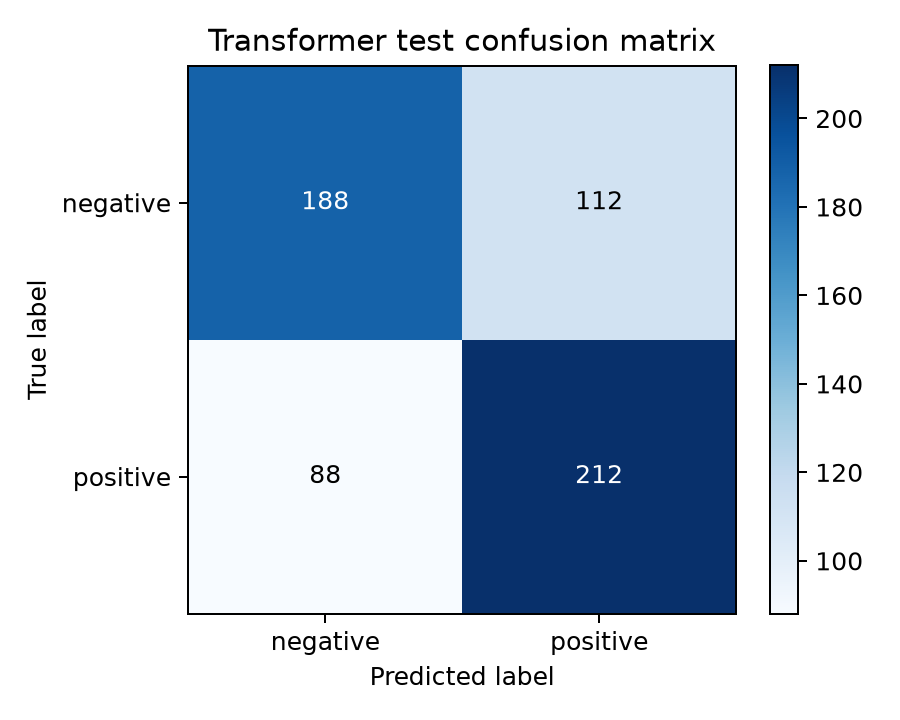

[[188 112]
 [ 88 212]]


In [14]:
test_result = base_run['test']
cm = confusion_matrix(test_result['truth'],test_result['prediction'],labels=[0,1])
fig,ax = plt.subplots(figsize=(5,4))
im = ax.imshow(cm,cmap='Blues')
ax.set(xticks=[0,1],yticks=[0,1],xticklabels=['negative','positive'],yticklabels=['negative','positive'],
       xlabel='Predicted label',ylabel='True label',title='Transformer test confusion matrix')
for (row,col),value in np.ndenumerate(cm):
    ax.text(col,row,str(value),ha='center',va='center',color='white' if value>cm.max()*0.65 else 'black')
fig.colorbar(im,ax=ax)
fig.tight_layout()
fig.savefig(LAB_DIR/'confusion_matrix.png',dpi=180)
plt.show()
print(cm)

## 26. Error analysis — 3 correct và 3 incorrect

In [15]:
analysis_frame = splits['test'].copy()
analysis_frame['prediction'] = test_result['prediction']
analysis_frame['p_positive'] = test_result['p_positive']
analysis_frame['correct'] = analysis_frame.label==analysis_frame.prediction
chosen = pd.concat([analysis_frame[analysis_frame.correct].head(3),analysis_frame[~analysis_frame.correct].head(3)])
error_rows = []
for row in chosen.itertuples():
    words = tokenize(row.text)
    ids,mask = encode_tokens(words,64)
    with torch.no_grad():
        _,weights = base_model(torch.tensor([ids],device=DEVICE),torch.tensor([mask],device=DEVICE),return_attention=True)
    valid_length = min(len(words),64)+1
    # Average over all valid query positions and heads; exclude CLS as a reported key.
    received = weights[0,:,:valid_length,1:valid_length].mean(dim=(0,1)).cpu().numpy()
    top_indices = received.argsort()[::-1][:5]
    error_rows.append({'row_id':row.Index,'label':row.label,'prediction':row.prediction,'p_positive':round(row.p_positive,6),
                       'tokens':len(words),'truncated':len(words)>64,
                       'top_attention_tokens':', '.join(words[index] for index in top_indices),
                       'preview':' '.join(row.text.split())[:500],'correct':row.correct})
error_examples = pd.DataFrame(error_rows)
print(error_examples.to_string(index=False))

 row_id  label  prediction  p_positive  tokens  truncated               top_attention_tokens                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                              preview  correct
      1      1           1    0.736641     112       True      b, full, style, produced, its Another one that slipped by the radar of most anyone. This little B produced gem is so full of new ideas in an old genre and so absolutely refreshing and inventive, that a dreadful feeling about the lack of cojones in today's cinema slowly overtakes your body. The final set piece is so innovative in its

**Ghi chú:** Top attention được tính trung bình trên heads và các query hợp lệ. Weight cao là một quan sát về model, chưa đủ chứng minh token đó gây ra prediction hoặc chứng minh model hiểu câu. Phân tích sáu mẫu được ghi trong error_analysis.md.

## 27. So sánh Lab 01 → Lab 07

| Representation | Word order | Context | Tương tác token | Giới hạn chính |
|---|---|---|---|---|
| TF-IDF | cục bộ nếu dùng n-gram | static | không trực tiếp | sparse, ít biểu diễn ngữ nghĩa |
| Average Word2Vec | mất thứ tự khi lấy trung bình | static | không trực tiếp | mất context và thứ tự |
| LSTM | có theo timestep | recurrent | qua hidden state | tuần tự, khó giữ thông tin rất xa |
| Attention Lab 06 | chưa có vị trí trong model đã làm | có theo tập token | trực tiếp | mean pooling không phân biệt permutation, O(T²) |
| Transformer | có PE | contextual | multi-head trực tiếp | O(T²), cần dữ liệu/training, vẫn bị truncation |

Lab 01 biểu diễn và truy hồi bằng TF-IDF; Lab 02 học xác suất sequence bằng n-gram nhưng gặp sparsity và context ngắn. Lab 03 học word vectors; Lab 04 dùng representation cho classification. Lab 05 bổ sung thứ tự và recurrent state. Lab 06 tạo tương tác trực tiếp giữa token. Lab 07 ghép position, nhiều head, FFN, residual và normalization thành encoder. Mỗi bước bổ sung khả năng, không bảo đảm luôn đạt metric tốt hơn bước trước.

## 28. Prediction verification

In [16]:
# Reuse trained models for an eval-only latency observation on the current device.
latency_rows = []
for length in [32,64,128,256]:
    ids = torch.randint(3,len(vocabulary),(8,length),device=DEVICE)
    mask = torch.ones_like(ids,dtype=torch.bool)
    for name,model in [('LSTM',lstm_run['model']),('Transformer',base_model)]:
        model.eval()
        durations = []
        with torch.no_grad():
            for iteration in range(13):
                if DEVICE.type=='cuda':
                    torch.cuda.synchronize()
                start = perf_counter()
                model(ids,mask)
                if DEVICE.type=='cuda':
                    torch.cuda.synchronize()
                if iteration>=3:
                    durations.append((perf_counter()-start)*1000)
        latency_rows.append({'model':name,'lexical_length':length,'median_forward_ms_batch8':np.median(durations)})
latency_table = pd.DataFrame(latency_rows)
display(latency_table.round(4))
pattern_diff = max(np.abs(head_matrices[i]-head_matrices[j]).max() for i in range(4) for j in range(i+1,4))
head_accuracy = head_table.sort_values('heads').accuracy.to_numpy()
head_monotonic = bool(np.all(np.diff(head_accuracy)>=0))
latency_pivot = latency_table.pivot(index='lexical_length',columns='model',values='median_forward_ms_batch8')
some_slower = bool((latency_pivot.Transformer>latency_pivot.LSTM).any())
verification_rows = [
    [1,'song song hơn RNN','kiến trúc không cập nhật recurrent state theo timestep','Phù hợp về kiến trúc','Latency không đo trực tiếp mức song song.'],
    [2,'không PE thì không có vị trí','permutation test không PE có representation gần như bằng nhau','Phù hợp','Các output token thay thứ tự theo input.'],
    [3,'mean pooling không phân biệt permutation','max diff không PE < 1e-5; có PE > 1e-5','Phù hợp','Chỉ áp dụng điều kiện eval và không đổi truncation.'],
    [4,'heads có thể khác pattern',f'max difference giữa hai head = {pattern_diff:.4f}','Phù hợp' if pattern_diff>1e-5 else 'Chưa quan sát được','Không gán ý nghĩa ngôn ngữ cho head.'],
    [5,'thêm heads không chắc tăng accuracy',str(head_table[['heads','accuracy']].to_dict('records')),'Phù hợp với lần chạy' if not head_monotonic else 'Chưa kết luận tổng quát','Một seed và dataset nhỏ chưa đủ chứng minh quy luật chung.'],
    [6,'không luôn nhanh hơn RNN','xem latency ở các length và training time mục 21','Có trường hợp Transformer chậm hơn' if some_slower else 'Chưa xác định ngoài phạm vi đo','Không suy ra mệnh đề phổ quát từ một máy.'],
]
display(pd.DataFrame(verification_rows,columns=['prediction','du_doan','ket_qua','doi_chieu','giai_thich']))

,model,lexical_length,median_forward_ms_batch8
0,LSTM,32,1.3880
1,Transformer,32,1.4060
2,LSTM,64,1.3134
3,Transformer,64,1.3017
4,LSTM,128,3.8580
5,Transformer,128,2.7710
6,LSTM,256,6.7565
7,Transformer,256,12.3922


,prediction,du_doan,ket_qua,doi_chieu,giai_thich
0,1,song song hơn RNN,kiến trúc không cập nhật recurrent state theo timestep,Phù hợp về kiến trúc,Latency không đo trực tiếp mức song song.
1,2,không PE thì không có vị trí,permutation test không PE có representation gần như bằng nhau,Phù hợp,Các output token thay thứ tự theo input.
2,3,mean pooling không phân biệt permutation,max diff không PE < 1e-5; có PE > 1e-5,Phù hợp,Chỉ áp dụng điều kiện eval và không đổi truncation.
3,4,heads có thể khác pattern,max difference giữa hai head = 0.9243,Phù hợp,Không gán ý nghĩa ngôn ngữ cho head.
4,5,thêm heads không chắc tăng accuracy,"[{'heads': 1, 'accuracy': 0.633333}, {'heads': 2, 'accuracy': 0.631667}, {'heads': 4, 'accuracy': 0.666667}, {'heads': 8, 'accuracy': 0.63}]",Phù hợp với lần chạy,Một seed và dataset nhỏ chưa đủ chứng minh quy luật chung.
5,6,không luôn nhanh hơn RNN,xem latency ở các length và training time mục 21,Có trường hợp Transformer chậm hơn,Không suy ra mệnh đề phổ quát từ một máy.


**Trả lời:** Prediction 1 phù hợp về kiến trúc; latency không trực tiếp đo mức song song. Prediction 2–3 phù hợp permutation experiment: không PE thì mean representation gần như không đổi; có PE thì khác. Prediction 4 phù hợp vì bốn head có pattern khác nhau.

Prediction 5 phù hợp vì accuracy không tăng đều theo số head. Prediction 6 có ví dụ hỗ trợ ở length 256: forward của Transformer mất khoảng 12.3922 ms, còn LSTM 6.7565 ms trên batch 8. Đây là latency forward trên máy hiện tại, khác với training time.

Chưa có quan sát trái dự đoán trong phạm vi thí nghiệm; các kết quả không chứng minh quy luật trên mọi dataset hay phần cứng. Dự đoán ban đầu được giữ nguyên trong prediction.md.

## 29. Learning curves

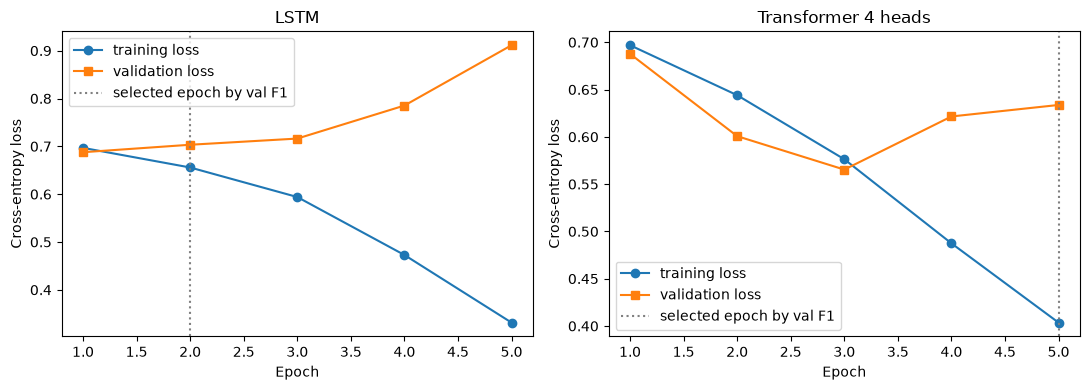

LSTM history


,epoch,training_loss,validation_loss,validation_f1
0,1,0.696789,0.687692,0.511464
1,2,0.655757,0.703321,0.638243
2,3,0.593996,0.716235,0.446809
3,4,0.472801,0.785301,0.534930
4,5,0.331393,0.911448,0.590164


Transformer history


,epoch,training_loss,validation_loss,validation_f1
0,1,0.696884,0.687720,0.671928
1,2,0.644017,0.600708,0.694329
2,3,0.576307,0.565363,0.699507
3,4,0.487406,0.621540,0.679443
4,5,0.403575,0.633702,0.711974


In [17]:
fig,axes = plt.subplots(1,2,figsize=(11,4))
for ax,(name,run) in zip(axes,[('LSTM',lstm_run),('Transformer 4 heads',base_run)]):
    history = run['history']
    ax.plot(history.epoch,history.training_loss,marker='o',label='training loss')
    ax.plot(history.epoch,history.validation_loss,marker='s',label='validation loss')
    ax.axvline(run['best_epoch'],color='gray',linestyle=':',label='selected epoch by val F1')
    ax.set(title=name,xlabel='Epoch',ylabel='Cross-entropy loss')
    ax.legend()
fig.tight_layout()
fig.savefig(LAB_DIR/'learning_curves.png',dpi=170)
plt.show()
print('LSTM history')
display(lstm_run['history'])
print('Transformer history')
display(base_run['history'])

**Trả lời:** LSTM có training loss giảm từ 0.6968 xuống 0.3314 nhưng validation loss tăng từ 0.6877 lên 0.9114; validation F1 cũng dao động. Đây là dấu hiệu overfitting và tổng quát hóa chưa ổn định.

Transformer có validation loss giảm tới 0.5654 ở epoch 3 rồi tăng lại, trong khi training loss tiếp tục giảm. Điều này gợi ý overfitting bắt đầu ở các epoch sau. Không thấy NaN hoặc loss bùng nổ trong output, nhưng 5 epoch chưa đủ khẳng định hội tụ hoàn toàn. Checkpoint chọn theo validation F1: epoch 2 cho LSTM, epoch 5 cho Transformer, không nhất thiết trùng epoch có validation loss nhỏ nhất.

## Tổng hợp results.csv

In [18]:
all_rows = []
all_rows.extend(result_row('heads',run) for run in head_runs.values())
all_rows.extend(result_row('architecture',run) for run in [lstm_run,base_run])
all_rows.extend(result_row('length',run) for run in length_runs.values())
all_rows.extend(result_row('pooling',run) for run in [base_run,cls_run])
results = pd.DataFrame(all_rows)
retained = length_table.set_index('max_length').tokens_retained_percent.to_dict()
results['tokens_retained_percent'] = results.max_length.map(retained).round(4)
results.to_csv(LAB_DIR/'results.csv',index=False)
print('Saved',len(results),'rows; repeated configurations reuse the same trained run.')
display(results)

Saved 12 rows; repeated configurations reuse the same trained run.


,experiment,model,heads,d_model,d_k,max_length,pooling,parameters,training_time_sec,epochs,best_epoch,validation_f1,train_samples,validation_samples,test_samples,vocabulary_size,accuracy,precision,recall,f1,tokens_retained_percent
0,heads,Transformer,1,128,128.0,64,mean,1156738,14.180,5,2,0.721053,1800,600,600,8000,0.633333,0.585837,0.910000,0.712794,26.9431
1,heads,Transformer,2,128,64.0,64,mean,1156738,13.522,5,2,0.712925,1800,600,600,8000,0.631667,0.587196,0.886667,0.706507,26.9431
2,heads,Transformer,4,128,32.0,64,mean,1156738,15.566,5,5,0.711974,1800,600,600,8000,0.666667,0.654321,0.706667,0.679487,26.9431
3,heads,Transformer,8,128,16.0,64,mean,1156738,20.778,5,2,0.737813,1800,600,600,8000,0.630000,0.586283,0.883333,0.704787,26.9431
4,architecture,LSTM,0,128,NaN,64,final_hidden,1156354,17.806,5,2,0.638243,1800,600,600,8000,0.541667,0.526539,0.826667,0.643320,26.9431
5,architecture,Transformer,4,128,32.0,64,mean,1156738,15.566,5,5,0.711974,1800,600,600,8000,0.666667,0.654321,0.706667,0.679487,26.9431
6,length,Transformer,4,128,32.0,32,mean,1156738,8.629,5,2,0.716502,1800,600,600,8000,0.611667,0.580336,0.806667,0.675035,13.6236
7,length,Transformer,4,128,32.0,64,mean,1156738,15.566,5,5,0.711974,1800,600,600,8000,0.666667,0.654321,0.706667,0.679487,26.9431
8,length,Transformer,4,128,32.0,128,mean,1156738,40.597,5,4,0.763754,1800,600,600,8000,0.738333,0.726984,0.763333,0.744715,50.7859
9,length,Transformer,4,128,32.0,256,mean,1156738,107.005,5,4,0.776256,1800,600,600,8000,0.770000,0.726257,0.866667,0.790274,76.3668


## AI assistance statement

Chi tiết được ghi trong README.md.